In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, Subset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
sklearn.set_config(display="text")

In [2]:
load_dotenv()

print(os.environ["KAGGLE_API_TOKEN"][:4])

KGAT


In [3]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

output_dir = r"C:\kdt_0900_osg\ml\resource\dataset"
os.makedirs(output_dir, exist_ok=True)
# https://www.kaggle.com/datasets/vesuvius13/formula-one-cars
api.dataset_download_files(r"vesuvius13/formula-one-cars", path=output_dir, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/vesuvius13/formula-one-cars
다운로드 완료


In [4]:
base_path = r"C:\kdt_0900_osg\ml\resource\dataset"
f1_path = os.path.join(base_path, "f1")

print("원본 폴더:", f1_path)
print("클래스 폴더:", os.listdir(f1_path))

원본 폴더: C:\kdt_0900_osg\ml\resource\dataset\f1
클래스 폴더: ['ferrari', 'mercedes']


In [5]:
f1_dataset = ImageFolder(f1_path)

print("클래스:", f1_dataset.classes)
print("전체 이미지:", len(f1_dataset))

클래스: ['ferrari', 'mercedes']
전체 이미지: 681


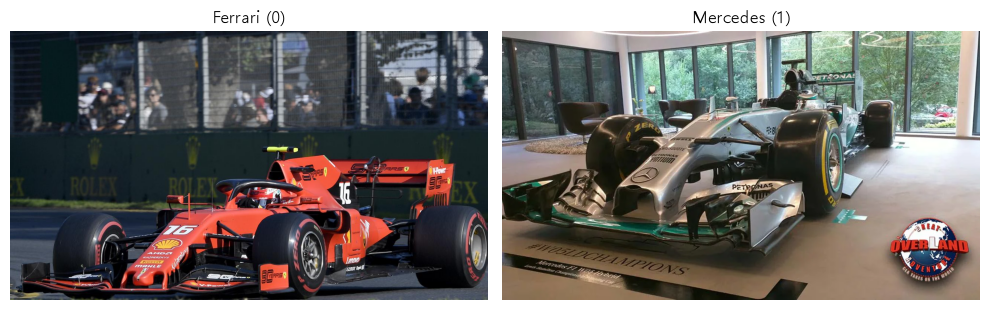

In [6]:
ferrari_path = f1_dataset.samples[0][0]
mercedes_idx = f1_dataset.targets.index(1)
mercedes_path = f1_dataset.samples[mercedes_idx][0]

ferrari_img = Image.open(ferrari_path)
mercedes_img = Image.open(mercedes_path)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(ferrari_img)
plt.title("Ferrari (0)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mercedes_img)
plt.title("Mercedes (1)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
total_size = len(f1_dataset)

train_size = int(total_size * 0.8)
val_size = total_size - train_size

train_split, val_split = random_split(f1_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(2026))

print("훈련 데이터 수:", len(train_split))
print("검증 데이터 수:", len(val_split))

훈련 데이터 수: 544
검증 데이터 수: 137


In [8]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [9]:
train_full = ImageFolder(f1_path, transform=train_transforms)
val_full = ImageFolder(f1_path, transform=test_transforms)

train_dataset = Subset(train_full, train_split.indices)
val_dataset = Subset(val_full, val_split.indices)

print("훈련 데이터 수:", len(train_dataset))
print("검증 데이터 수:", len(val_dataset))

훈련 데이터 수: 544
검증 데이터 수: 137


In [10]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [11]:
images, labels = next(iter(train_loader))

print("이미지 크기:", images.shape)
print("라벨 크기:", labels.shape)
print("Train 배치 수:", len(train_loader))
print("Validation 배치 수:", len(val_loader))

이미지 크기: torch.Size([32, 3, 224, 224])
라벨 크기: torch.Size([32])
Train 배치 수: 17
Validation 배치 수: 5


In [12]:
print("클래스 수:", len(f1_dataset.classes))
print("라벨 매핑:", f1_dataset.class_to_idx)

train_labels = [f1_dataset.targets[i] for i in train_split.indices]
val_labels = [f1_dataset.targets[i] for i in val_split.indices]

print("Train Ferrari:", train_labels.count(0))
print("Train Mercedes:", train_labels.count(1))

print("Validation Ferrari:", val_labels.count(0))
print("Validation Mercedes:", val_labels.count(1))

클래스 수: 2
라벨 매핑: {'ferrari': 0, 'mercedes': 1}
Train Ferrari: 303
Train Mercedes: 241
Validation Ferrari: 62
Validation Mercedes: 75


In [13]:
model1 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
print(model1)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [14]:
print("GAP:", model1.avgpool)
print("기존 분류기:", model1.fc)
print("분류기 입력 특징 수:", model1.fc.in_features)

GAP: AdaptiveAvgPool2d(output_size=(1, 1))
기존 분류기: Linear(in_features=512, out_features=1000, bias=True)
분류기 입력 특징 수: 512


In [15]:
for param in model1.parameters():
    param.requires_grad = False

In [16]:
num_classes = 2
in_features = model1.fc.in_features
model1.avgpool = nn.AdaptiveAvgPool2d((1, 1))

model1.fc = nn.Sequential(nn.Dropout(p=0.3), nn.Linear(in_features, num_classes))

print(model1.avgpool)
print(model1.fc)

AdaptiveAvgPool2d(output_size=(1, 1))
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=512, out_features=2, bias=True)
)


In [17]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cpu


In [18]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model1.fc.parameters(), lr=0.001)

In [19]:
def train_one_epoch_classification(model, dataloader, criterion, optimizer, device="cpu"):
    model.train()

    for name, module in model.named_modules():
        if not name.startswith("fc") and isinstance(module, nn.BatchNorm2d):
            module.eval()

    sum_losses = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)

        loss.backward()
        optimizer.step()

        sum_losses += loss.item() * X_batch.size(0)

        pred = y_pred.argmax(dim=1)
        correct += (pred == y_batch).sum().item()
        total += y_batch.size(0)

    avg_loss = sum_losses / total
    accuracy = correct / total

    return avg_loss, accuracy

In [20]:
@torch.no_grad()
def evaluate_classification(model, dataloader, criterion, device="cpu"):
    model.eval()

    sum_losses = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)

        sum_losses += loss.item() * X_batch.size(0)

        pred = y_pred.argmax(dim=1)
        correct += (pred == y_batch).sum().item()
        total += y_batch.size(0)

    avg_loss = sum_losses / total
    accuracy = correct / total

    return avg_loss, accuracy

In [21]:
def train_model_classification(
    model, model_name, train_loader, val_loader,
    criterion, optimizer, epochs, device, save_base_dir
):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_acc = -1.0

    print(f"===== {model_name} 학습 시작 =====")

    for epoch in range(epochs):

        train_loss, train_acc = train_one_epoch_classification(model, train_loader, criterion, optimizer, device)

        val_loss, val_acc = evaluate_classification(model, val_loader, criterion, device)

        print(
            f"[Epoch {epoch + 1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # 검증 정확도가 높아졌을 때만 저장
        if val_acc > best_val_acc:
            best_val_acc = val_acc

            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

            print(f"Best Model 저장! Val Acc: {val_acc:.4f}")

    print(f"===== {model_name} 학습 종료 =====")

    return history

In [22]:
history1 = train_model_classification(
    model=model1,
    model_name="ResNet18-F1",
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=10,
    device=device,
    save_base_dir=os.path.join(base_path, "weights")
)

===== ResNet18-F1 학습 시작 =====
[Epoch 1/10] Train Loss: 0.6576 | Train Acc: 0.6379 | Val Loss: 0.5100 | Val Acc: 0.8467
Best Model 저장! Val Acc: 0.8467
[Epoch 2/10] Train Loss: 0.4419 | Train Acc: 0.7960 | Val Loss: 0.3203 | Val Acc: 0.9343
Best Model 저장! Val Acc: 0.9343
[Epoch 3/10] Train Loss: 0.3096 | Train Acc: 0.9118 | Val Loss: 0.2396 | Val Acc: 0.9489
Best Model 저장! Val Acc: 0.9489
[Epoch 4/10] Train Loss: 0.2574 | Train Acc: 0.9062 | Val Loss: 0.2050 | Val Acc: 0.9562
Best Model 저장! Val Acc: 0.9562
[Epoch 5/10] Train Loss: 0.2230 | Train Acc: 0.9338 | Val Loss: 0.2053 | Val Acc: 0.9489
[Epoch 6/10] Train Loss: 0.1949 | Train Acc: 0.9467 | Val Loss: 0.2139 | Val Acc: 0.9489
[Epoch 7/10] Train Loss: 0.1794 | Train Acc: 0.9449 | Val Loss: 0.1701 | Val Acc: 0.9562
[Epoch 8/10] Train Loss: 0.1769 | Train Acc: 0.9393 | Val Loss: 0.1828 | Val Acc: 0.9489
[Epoch 9/10] Train Loss: 0.1530 | Train Acc: 0.9559 | Val Loss: 0.1960 | Val Acc: 0.9489
[Epoch 10/10] Train Loss: 0.1770 | Train Acc:

In [23]:
print(f"Train Accuracy: {history1['train_acc'][-1] * 100:.2f}%")
print(f"Validation Accuracy: {history1['val_acc'][-1] * 100:.2f}%")

Train Accuracy: 95.04%
Validation Accuracy: 94.89%


In [24]:
best_model_path = os.path.join(base_path, "weights", "ResNet18-F1", "best_model.pth")

print("Best 모델 존재 여부:", os.path.exists(best_model_path))
print("저장 경로:", best_model_path)

Best 모델 존재 여부: True
저장 경로: C:\kdt_0900_osg\ml\resource\dataset\weights\ResNet18-F1\best_model.pth


In [25]:
best_model_path = os.path.join(base_path, "weights", "ResNet18-F1", "best_model.pth")

model1.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=True))

model1.to(device)
model1.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [26]:
val_loss, val_acc = evaluate_classification(model1, val_loader, criterion, device)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc * 100:.2f}%")

Validation Loss: 0.2050
Validation Accuracy: 95.62%


In [27]:
y_true = []
y_pred = []

model1.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model1(images)
        preds = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(preds.cpu().tolist())

f1 = f1_score(y_true, y_pred, average="macro")

print(f"F1-score: {f1:.4f}")

F1-score: 0.9560


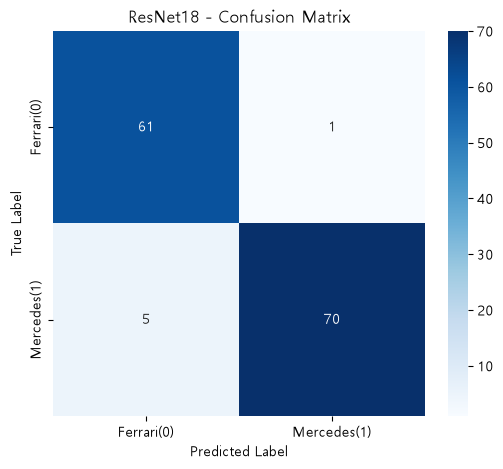

In [28]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
cm

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ferrari(0)", "Mercedes(1)"],
    yticklabels=["Ferrari(0)", "Mercedes(1)"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ResNet18 - Confusion Matrix")
plt.show()

In [29]:
incorrect_samples = []
wrong_indices = []

model1.eval()
idx = 0

with torch.no_grad():
    for imgs, labels in val_loader:
        imgs_device = imgs.to(device)

        preds = model1(imgs_device)
        pred_labels = preds.argmax(dim=1).cpu()
        probs = torch.softmax(preds, dim=1).cpu()

        incorrect_mask = (pred_labels != labels)

        for i in range(len(labels)):
            if incorrect_mask[i]:
                wrong_indices.append(idx + i)

                incorrect_samples.append({
                    "img": imgs[i],
                    "true_label": labels[i].item(),
                    "pred_label": pred_labels[i].item(),
                    "prob": probs[i][pred_labels[i]].item()
                })

        idx += len(labels)

print("오분류 이미지 수:", len(incorrect_samples))
print("오분류 인덱스:", wrong_indices)

오분류 이미지 수: 6
오분류 인덱스: [26, 33, 40, 62, 84, 123]


In [30]:
print(f"Validation Accuracy: {(137 - len(incorrect_samples)) / 137 * 100:.2f}%")

Validation Accuracy: 95.62%
